# Modelo SIR resuelto con PyMC

PyMC es una biblioteca de programación probabilística en Python diseñada para realizar inferencia bayesiana. En lugar de calcular un único valor exacto mediante optimización clásica, PyMC utiliza algoritmos de muestreo iterativo, como MCMC (Markov Chain Monte Carlo), para explorar miles de escenarios y devolver una distribución de probabilidad que indica cuáles valores son los más factibles para las incógnitas de un problema, cuantificando su nivel de incertidumbre.

En el caso específico del modelo epidemiológico SIR, estructuramos el uso de PyMC en cuatro piezas fundamentales:

* **Definición de Priors (Conocimiento a priori):** Le indicamos al modelo qué rango de valores esperamos inicialmente para los parámetros desconocidos asignándoles distribuciones estadísticas (usamos `HalfNormal` para asegurar que la tasa de infección $\beta$ y la tasa de recuperación $\gamma$ siempre fueran positivas).
* **Motor Dinámico (Simulador):** Utilizamos `pytensor.scan`, que es el motor de cálculo interno de PyMC, para resolver las ecuaciones diferenciales del modelo SIR paso a paso en el tiempo (método de Euler). Esto genera una curva teórica de contagios calculada dinámicamente según los parámetros propuestos.
* **Verosimilitud (Likelihood):** Conectamos esa curva teórica limpia con nuestros datos reales imperfectos utilizando una distribución de Poisson, que es ideal para modelar conteos (como el número de personas infectadas cada día). Esto le enseña a PyMC a evaluar numéricamente qué tan bien encaja su simulación con la realidad.
* **Muestreo (Inferencia):** Al ejecutar `pm.sample()`, PyMC comienza a probar aleatoria pero inteligentemente miles de combinaciones de $\beta$ y $\gamma$. Las combinaciones que generan curvas que coinciden bien con los puntos de los datos observados son aceptadas con mayor frecuencia. Al terminar, agrupa todas las estimaciones exitosas para darnos el valor promedio y la dispersión estadística de cada parámetro.

A continuación ponemos en práctica la librería para resolver el model SIR:

C:\Users\ebero\AppData\Local\Temp\ipykernel_25860\1577484018.py:56: DeprecationWarning: Scan return signature will change. Updates dict will not be returned, only the first argument. Pass `return_updates=False` to conform to the new API and avoid this warning
  outputs, _ = pytensor.scan(


Iniciando muestreo MCMC...


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [beta, gamma]


c:\Users\ebero\OneDrive\Documents\codiguines\.venv\Lib\site-packages\rich\live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 12 seconds.


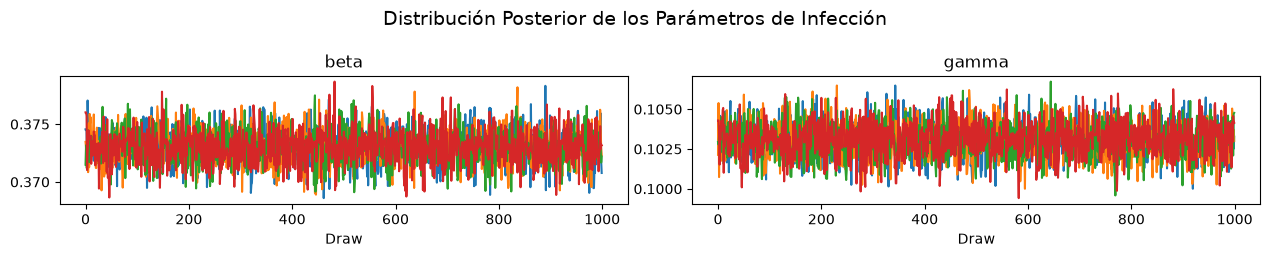

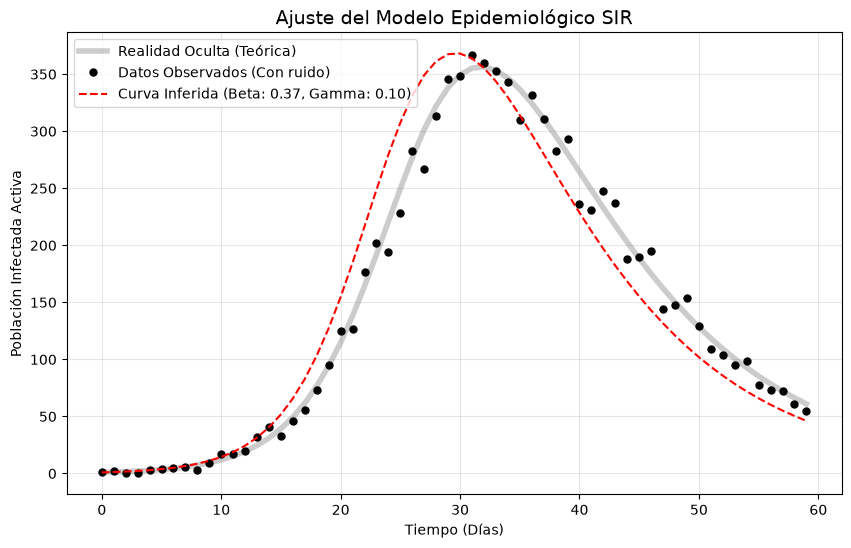

In [3]:
import numpy as np
import pymc as pm
import pytensor
import pytensor.tensor as pt
import arviz as az
import matplotlib.pyplot as plt
from scipy.integrate import odeint

# 1. Función diferencial del SIR
def sir_ode(y, t, beta, gamma, N):
    S, I, R = y
    dSdt = -beta * S * I / N
    dIdt = beta * S * I / N - gamma * I
    dRdt = gamma * I
    return dSdt, dIdt, dRdt


if __name__ == '__main__':
    # Configuramos la iniciación y los datos Sintéticos
    N = 1000
    I0, R0 = 1, 0
    S0 = N - I0 - R0

    beta1 = 0.35 
    gamma1 = 0.1 
    t_dias = np.arange(0, 60, 1)

    # Generar la verdad con SciPy
    sol_verdadera = odeint(sir_ode, (S0, I0, R0), t_dias, args=(beta1, gamma1, N))
    _, I_true, _ = sol_verdadera.T

    # Añadir ruido estadístico para simular datos reales.
    np.random.seed(42)
    I_obs = np.random.poisson(I_true)

    # 3. Modelo Bayesiano en PyMC
    with pm.Model() as sir_modelo:
        # Priors (Distribuciones a priori)
        beta = pm.HalfNormal('beta', sigma=1.0)
        gamma = pm.HalfNormal('gamma', sigma=1.0)
        
        # Variables constantes para PyTensor
        S_init = pt.as_tensor_variable(np.float64(S0))
        I_init = pt.as_tensor_variable(np.float64(I0))
        N_tensor = pt.as_tensor_variable(np.float64(N))
        
        # Paso de Euler para la aproximación diferencial
        def euler_step(S_t, I_t, b, g, pop):
            dS = -b * S_t * I_t / pop
            dI = b * S_t * I_t / pop - g * I_t
            S_next = pt.clip(S_t + dS, 0.0, pop)
            I_next = pt.clip(I_t + dI, 0.0, pop)
            return S_next, I_next

        # Bucle iterativo de simulación interna
        outputs, _ = pytensor.scan(
            fn=euler_step,
            outputs_info=[S_init, I_init],
            non_sequences=[beta, gamma, N_tensor],
            n_steps=len(t_dias) - 1
        )
        
        # Reconstruir la serie temporal
        I_simulado = pt.concatenate([[I_init], outputs[1]])
        
        # Aplicamos verosimilitud (Ajuste a los datos observados)
        pm.Poisson(
            'observaciones', 
            mu=pt.clip(I_simulado, 0.001, np.float64(N)), 
            observed=I_obs
        )
        
        #Muestreo (Inferencia) - cores=1
        print("Iniciando muestreo MCMC...")
        trace = pm.sample(draws=1000, tune=1000, cores=4, return_inferencedata=True)

    # Para visualizar los resultados
    # Gráfico 1: MCMC
    az.plot_trace(trace)
    plt.suptitle("Distribución Posterior de los Parámetros de Infección", fontsize=14)
    plt.tight_layout()
    plt.show()

    # Gráfico 2: Predicción posterior vs Datos reales
    beta_est = trace.posterior['beta'].mean().item()
    gamma_est = trace.posterior['gamma'].mean().item()

    sol_estimada = odeint(sir_ode, (S0, I0, R0), t_dias, args=(beta_est, gamma_est, N))
    _, I_est, _ = sol_estimada.T

    plt.figure(figsize=(10, 6))
    plt.plot(t_dias, I_true, 'gray', alpha=0.4, linewidth=4, label='Realidad Oculta (Teórica)')
    plt.plot(t_dias, I_obs, 'ko', label='Datos Observados (Con ruido)', markersize=5)
    plt.plot(t_dias, I_est, 'r--', label=f'Curva Inferida (Beta: {beta_est:.2f}, Gamma: {gamma_est:.2f})')
    plt.title('Ajuste del Modelo Epidemiológico SIR', fontsize=14)
    plt.xlabel('Tiempo (Días)')
    plt.ylabel('Población Infectada Activa')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

Las gráficas presentadas muestran los resultados de dos etapas clave del código: el proceso de inferencia bayesiana y la simulación predictiva final.

**Gráficas superiores ("beta" y "gamma") - Trazas de MCMC**
Estas dos gráficas representan el proceso de búsqueda matemática que hizo PyMC para encontrar los valores más probables de la tasa de infección ($\beta$) y la tasa de recuperación ($\gamma$).

* **En el eje X** Representamos el número de iteraciones o pasos de muestreo que dio el algoritmo (de 0 a 1000).


* **En el eje Y:** se muestra el valor numérico estimado para el parámetro en cada iteración.


* Las múltiples líneas de colores que oscilan formando una franja densa indican que el modelo ha convergido de manera estable, esto significa que el algoritmo encontró con seguridad el rango real de los parámetros ocultos, estimando $\beta$ alrededor de 0.372 y $\gamma$ alrededor de 0.103.



**Gráfica inferior - Ajuste del Modelo Epidemiológico SIR**
En esta gráfica visualizamos como se comporta la epidemia en el tiempo comparando la realidad con la predicción matemática que logró deducir el modelo.

* **Los puntos negros** representan los datos sintéticos con ruido que le dimos al modelo para entrenarlo.


* **La línea gris gruesa** es la curva epidemiológica verdadera y exacta generada al principio sin ruido, en un escenario real de salud pública, esta curva no se conoce, pero aquí sirve para verificar si el modelo acertó.


* **La línea roja punteada** es la curva que construyó nuestro modelo utilizando los valores promediados de $\beta$ (0.37) y $\gamma$ (0.10) que descubrió en las gráficas superiores.


* El hecho de que la curva roja punteada siga tan de cerca a los puntos negros y a la línea gris demuestra que el modelo bayesiano fue capaz de "ver a través del ruido" y recuperar con éxito la dinámica real del brote infeccioso.